In [2]:


import os

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

import statsmodels.api as sm

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, KFold, GridSearchCV

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

In [4]:
df = pd.read_csv("data/loan_prediction.csv", index_col='Loan_ID')
df

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y


In [5]:
df.info()


<class 'pandas.DataFrame'>
Index: 614 entries, LP001002 to LP002990
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             601 non-null    str    
 1   Married            611 non-null    str    
 2   Dependents         599 non-null    str    
 3   Education          614 non-null    str    
 4   Self_Employed      582 non-null    str    
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         592 non-null    float64
 8   Loan_Amount_Term   600 non-null    float64
 9   Credit_History     564 non-null    float64
 10  Property_Area      614 non-null    str    
 11  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(7)
memory usage: 62.4+ KB


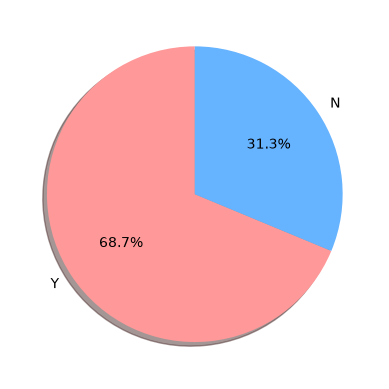

In [8]:
df['Loan_Status'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90, shadow=True)
plt.show()

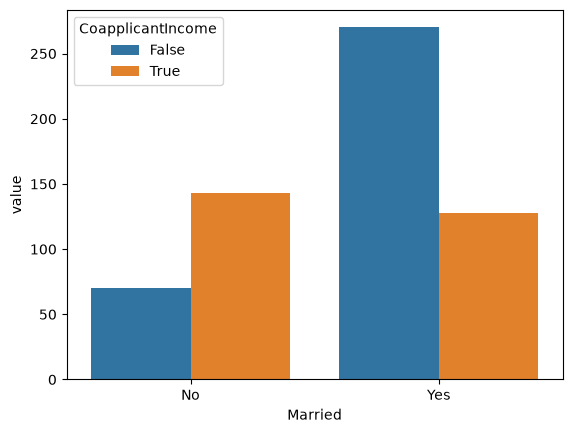

In [6]:
married_income = pd.crosstab(df['Married'], (df["CoapplicantIncome"]==0))

stacked = married_income.stack().reset_index().rename(columns={0:"value"})
sns.barplot(x = stacked.Married, y = stacked.value, hue = stacked.CoapplicantIncome)
plt.show()

applicant = Orang pertama yang mengajukan pinjaman atau kredit.


coapplicant = Orang kedua yang ikut serta dalam pengajuan tersebut.

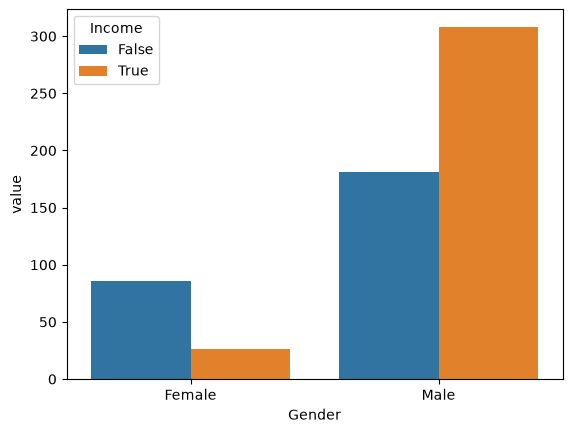

In [ ]:
# ini menikah
married_yes = pd.crosstab(df['Gender'], (df['Married']=='Yes') & (df['ApplicantIncome'] > df['CoapplicantIncome']))

married_stacked = married_yes.stack().reset_index().rename(columns={0:"value", "col_0" : 'Income'})
married_stacked

sns.barplot(x = married_stacked.Gender, y = married_stacked.value, hue = married_stacked.Income)
plt.show()

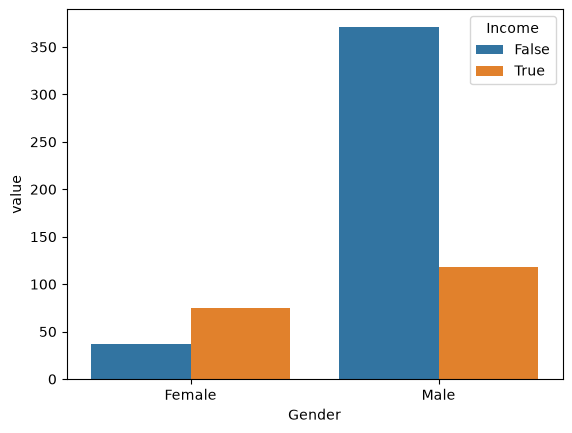

In [ ]:
# ini ga menikah
married_yes = pd.crosstab(df['Gender'], (df['Married']=='No') & (df['ApplicantIncome'] > df['CoapplicantIncome']))

married_stacked = married_yes.stack().reset_index().rename(columns={0:"value", "col_0" : 'Income'})
married_stacked

sns.barplot(x = married_stacked.Gender, y = married_stacked.value, hue = married_stacked.Income)
plt.show()

In [10]:
gender_dependent = pd.crosstab([df["Gender"], df["Married"]], (df['Dependents']=="0"))
gender_dependent

Dependents      False  True 
Gender Married              
Female No          20     60
       Yes         11     20
Male   No          21    109
       Yes        208    149

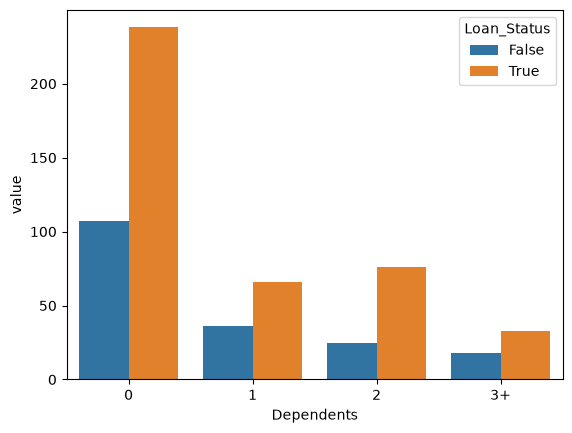

In [12]:
loan_y = pd.crosstab(df['Dependents'], (df["Loan_Status"]=="Y"))
loan_stacked = loan_y.stack().reset_index().rename(columns={0:"value"})
sns.barplot(x = loan_stacked.Dependents, y = loan_stacked.value, hue = loan_stacked.Loan_Status)
plt.show()

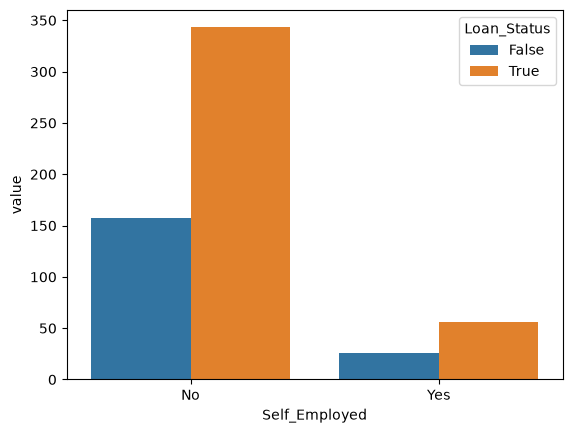

In [14]:
employ_y = pd.crosstab(df['Self_Employed'], (df["Loan_Status"]=="Y"))

employ_stacked = employ_y.stack().reset_index().rename(columns={0:"value"})
sns.barplot(x = employ_stacked.Self_Employed, y = employ_stacked.value, hue = employ_stacked.Loan_Status)
plt.show()

## Preprocessing Data 

In [15]:
# cek missing value
df.isnull().sum()

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [16]:
# handdling missing valur untuk married 
# membuat kondisi bagi missing value dengan keadaan coaplicant tidak kosong
married_status = ((df["Married"].isnull()) & (df['CoapplicantIncome'] != 0 ))

# jika kondisi benar married dan memiliki coapplicant maka status menikah
df.loc[married_status, "Married"] == "Yes"

# jika tisak memenuhi kondisi maka belum menikah
df.loc[df["Married"].isnull(), "Married"] = "No"

In [17]:
# handdling missing value untuk gender 
married_male = ((df["Gender"].isnull() & (df["Married"]=="Yes")) & (df['ApplicantIncome'] > df["CoapplicantIncome"]))
married_female = ((df["Gender"].isnull() & (df["Married"]=="Yes")) & (df['ApplicantIncome'] < df["CoapplicantIncome"]))
no_married_male = ((df["Gender"].isnull() & (df["Married"]=="No")) & (df['ApplicantIncome'] > df["CoapplicantIncome"]))
no_married_female = ((df["Gender"].isnull() & (df["Married"]=="No")) & (df['ApplicantIncome'] < df["CoapplicantIncome"]))

df.loc[married_male, "Gender"] = "Male"
df.loc[married_female, "Gender"] = "Female"
df.loc[no_married_male, "Gender"] = "Male"
df.loc[no_married_female, "Gender"] = "Female"


In [19]:
# handdling missing value untuk dependent
# membuat kondisi bagi missing value dengan keaadan tanggungan
dependents_male = (((df["Dependents"].isnull()) & (df["Gender"]=="Male")) & (df["Married"]=="Yes"))

# jika kondisi terpenuhi maka pilihlah modus
a = df[(df['Gender']=="Male") & (df["Dependents"] != "0")]
a_1 = a["Dependents"].value_counts().index[0]
df.loc[dependents_male, "Dependents"] = a_1

df.loc[df["Dependents"].isnull(), "Dependents"] = "0"

In [20]:
mmodus = ["Self_Employed", "Credit_History"]
mmean = [
    "Loan_Amount_Term",
    "LoanAmount",
    "CoapplicantIncome",
    "ApplicantIncome",
]

for feature in mmean:
  if feature in df.columns.values:
    df[feature] = df[feature].fillna(df[feature].mean())

for feature in mmodus:
  if feature in df.columns.values:
    df[feature] = df[feature].fillna(df[feature].value_counts().index[0])

df.isna().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64